In [16]:
import pandas as pd
import numpy as np

from google.colab import drive
drive.mount('/content/drive')

FILE_PATH = "/content/drive/MyDrive/Revenue_Intelligence_Project/Data/customer_analytics.csv"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [17]:
df = pd.read_csv(FILE_PATH)

print(df.shape)
df.head()

(779495, 9)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


In [18]:
print("Rows:", len(df))

print("Customers:", df["Customer ID"].nunique())

print("Invoices:", df["Invoice"].nunique())

Rows: 779495
Customers: 5881
Invoices: 36975


In [19]:
print(
    "Total Revenue:",
    round(df["Revenue"].sum(), 2)
)

Total Revenue: 17374804.27


In [20]:
total_revenue = df["Revenue"].sum()

total_orders = df["Invoice"].nunique()

aov = total_revenue / total_orders

print("AOV:", round(aov, 2))

AOV: 469.91


In [21]:
customer_revenue = (
    df.groupby("Customer ID")["Revenue"]
      .sum()
      .reset_index()
)

customer_revenue.head()

,Customer ID,Revenue
0,12346.0,77556.46
1,12347.0,4921.53
2,12348.0,2019.40
3,12349.0,4428.69
4,12350.0,334.40


In [22]:
customer_revenue["Revenue"].describe()

,Revenue
count,5881.000000
mean,2954.396237
std,14437.322635
min,0.000000
25%,341.900000
50%,865.600000
75%,2247.720000
max,580987.040000


In [23]:
customer_orders = (
    df.groupby("Customer ID")["Invoice"]
      .nunique()
      .reset_index()
)

customer_orders.columns = [
    "Customer ID",
    "Order Count"
]

customer_orders.head()

,Customer ID,Order Count
0,12346.0,12
1,12347.0,8
2,12348.0,5
3,12349.0,4
4,12350.0,1


In [24]:
customer_orders["Order Count"].describe()

,Order Count
count,5881.000000
mean,6.287196
std,13.012879
min,1.000000
25%,1.000000
50%,3.000000
75%,7.000000
max,398.000000


In [25]:
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"]
)

In [26]:
df["YearMonth"] = (
    df["InvoiceDate"]
    .dt.to_period("M")
    .astype(str)
)

In [27]:
monthly_revenue = (
    df.groupby("YearMonth")["Revenue"]
      .sum()
      .reset_index()
)

monthly_revenue.head()

,YearMonth,Revenue
0,2009-12,683504.010
1,2010-01,555802.672
2,2010-02,504558.956
3,2010-03,696978.471
4,2010-04,591982.002


In [28]:
monthly_customers = (
    df.groupby("YearMonth")["Customer ID"]
      .nunique()
      .reset_index()
)

monthly_customers.head()

,YearMonth,Customer ID
0,2009-12,955
1,2010-01,720
2,2010-02,774
3,2010-03,1057
4,2010-04,942


In [29]:
top_customers = (
    customer_revenue
    .sort_values(
        "Revenue",
        ascending=False
    )
    .head(10)
)

top_customers

,Customer ID,Revenue
5695,18102.0,580987.04
2279,14646.0,528602.52
1791,14156.0,313437.62
2541,14911.0,291420.81
5053,17450.0,244784.25
1332,13694.0,195640.69
5112,17511.0,172132.87
4064,16446.0,168472.50
4298,16684.0,147142.77
68,12415.0,144458.37


Revenue Trend Chart

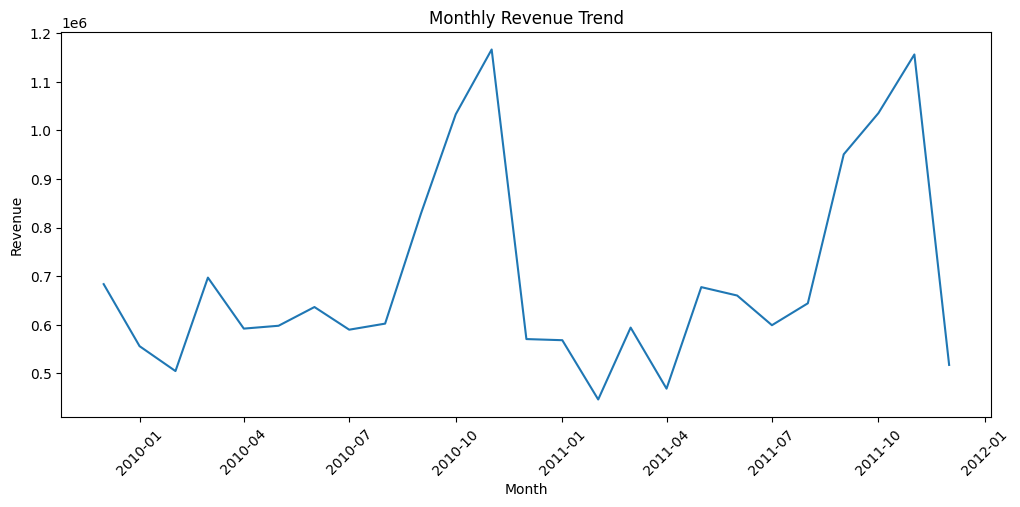

In [30]:
import matplotlib.pyplot as plt

monthly_revenue["YearMonth"] = pd.to_datetime(
    monthly_revenue["YearMonth"]
)

plt.figure(figsize=(12,5))

plt.plot(
    monthly_revenue["YearMonth"],
    monthly_revenue["Revenue"]
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)

plt.show()

Customer Trend Chart

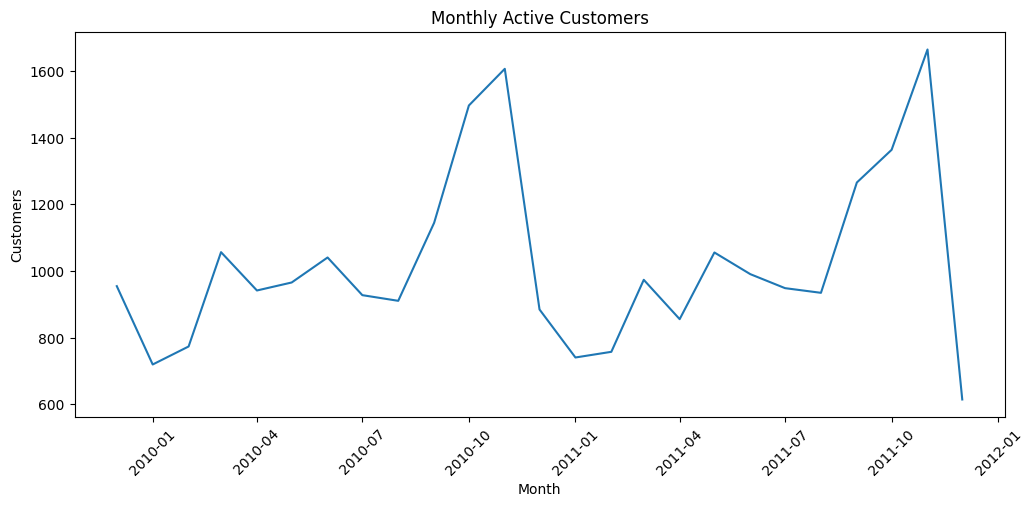

In [31]:
monthly_customers["YearMonth"] = pd.to_datetime(
    monthly_customers["YearMonth"]
)

plt.figure(figsize=(12,5))

plt.plot(
    monthly_customers["YearMonth"],
    monthly_customers["Customer ID"]
)

plt.title("Monthly Active Customers")
plt.xlabel("Month")
plt.ylabel("Customers")

plt.xticks(rotation=45)

plt.show()